<a href="https://colab.research.google.com/github/subodhbhatta67/LinearRegression01/blob/main/firstmodel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
from google.colab import userdata
import requests
import pandas as pd
from io import StringIO

# Get your GitHub token securely
token = userdata.get('GITHUB_TOKEN')

# GitHub repository details
username = "subodhbhatta67"
repo = "LinearRegression01"
filename = "signups.csv"

url = f"https://api.github.com/repos/{username}/{repo}/contents/{filename}?ref=main"

headers = {
    "Authorization": f"Bearer {token}",
    "Accept": "application/vnd.github.raw"
}

response = requests.get(url, headers=headers)

response.raise_for_status()

df = pd.read_csv(StringIO(response.text))

# EDA


In [7]:
df.head()


,user_id,email,name,signup_date,plan,country,age,spend,newsletter
0,U2067,grace3@example.com,grace,7/23/2025,Pro,DE,43.0,955 INR,N
1,U2109,ada17@example.com,ada,16/09/2025,FREE,UK,38.0,581.25,NaN
2,U2066,ALICE6@EXAMPLE.COM,alice,2025-09-01,Free,us,42.0,561.13,NaN
3,U2245,margaret42@example.com,margaret,2025-02-02,Team,UK,27.0,1554 INR,NaN
4,U2107,margaret35@example.com,Margaret,08/10/2025,Pro,us,43.0,1594 INR,yes


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   user_id      414 non-null    object 
 1   email        414 non-null    object 
 2   name         414 non-null    object 
 3   signup_date  414 non-null    object 
 4   plan         414 non-null    object 
 5   country      414 non-null    object 
 6   age          376 non-null    float64
 7   spend        387 non-null    object 
 8   newsletter   358 non-null    object 
dtypes: float64(1), object(8)
memory usage: 29.2+ KB


In [9]:
df.shape

(414, 9)

In [10]:
df.duplicated().sum()

np.int64(14)

In [11]:
df = df.drop_duplicates()

In [12]:
df.shape

(400, 9)

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.isnull().sum()



,0
user_id,0
email,0
name,0
signup_date,0
plan,0
country,0
age,38
spend,26
newsletter,56


In [15]:
df.describe()

,age
count,362.000000
mean,46.149171
std,30.227940
min,-5.000000
25%,30.000000
50%,43.000000
75%,59.000000
max,320.000000


In [16]:
df.columns

Index(['user_id', 'email', 'name', 'signup_date', 'plan', 'country', 'age',
       'spend', 'newsletter'],
      dtype='object')

In [17]:
df['country'].value_counts()

,count
country,
de,57
UK,54
DE,50
us,49
IN,48
uk,44
in,36
US,33
IN,29


In [18]:
df['name'] = df['name'].str.strip().str.lower()

In [19]:
df.head()

,user_id,email,name,signup_date,plan,country,age,spend,newsletter
0,U2067,grace3@example.com,grace,7/23/2025,Pro,DE,43.0,955 INR,N
1,U2109,ada17@example.com,ada,16/09/2025,FREE,UK,38.0,581.25,NaN
2,U2066,ALICE6@EXAMPLE.COM,alice,2025-09-01,Free,us,42.0,561.13,NaN
3,U2245,margaret42@example.com,margaret,2025-02-02,Team,UK,27.0,1554 INR,NaN
4,U2107,margaret35@example.com,margaret,08/10/2025,Pro,us,43.0,1594 INR,yes


In [20]:
df['plan'] = df['plan'].str.strip().str.lower()


In [21]:
df['country'] = df['country'].str.strip().str.upper()

In [22]:
df['email'] = df['email'].str.strip().str.lower()

In [23]:
df.head()

,user_id,email,name,signup_date,plan,country,age,spend,newsletter
0,U2067,grace3@example.com,grace,7/23/2025,pro,DE,43.0,955 INR,N
1,U2109,ada17@example.com,ada,16/09/2025,free,UK,38.0,581.25,NaN
2,U2066,alice6@example.com,alice,2025-09-01,free,US,42.0,561.13,NaN
3,U2245,margaret42@example.com,margaret,2025-02-02,team,UK,27.0,1554 INR,NaN
4,U2107,margaret35@example.com,margaret,08/10/2025,pro,US,43.0,1594 INR,yes


In [24]:
df['newsletter'] = df['newsletter'].str.strip().str.lower()

In [25]:
df.head()


,user_id,email,name,signup_date,plan,country,age,spend,newsletter
0,U2067,grace3@example.com,grace,7/23/2025,pro,DE,43.0,955 INR,n
1,U2109,ada17@example.com,ada,16/09/2025,free,UK,38.0,581.25,NaN
2,U2066,alice6@example.com,alice,2025-09-01,free,US,42.0,561.13,NaN
3,U2245,margaret42@example.com,margaret,2025-02-02,team,UK,27.0,1554 INR,NaN
4,U2107,margaret35@example.com,margaret,08/10/2025,pro,US,43.0,1594 INR,yes


In [26]:
df['newsletter'].value_counts()

,count
newsletter,
n,66
y,66
false,62
no,59
true,49
yes,42


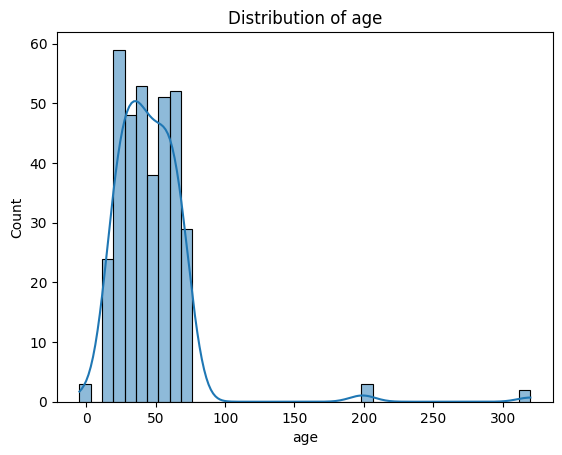

In [27]:
sns.histplot(data=df, x='age', kde=True)
plt.title(f'Distribution of {'age'}')
plt.show()

In [28]:
df.loc[(df['age'] <= 0) | (df['age'] > 120), 'age'] = np.nan

In [29]:
df['age']

,age
0,43.0
1,38.0
2,42.0
3,27.0
4,43.0
...,...
408,22.0
410,57.0
411,32.0
412,65.0


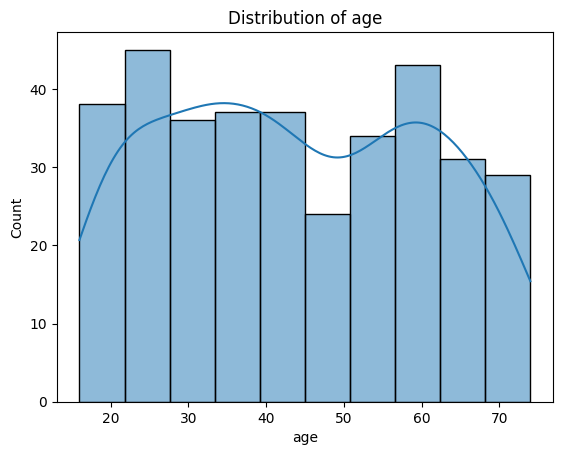

In [30]:
sns.histplot(data=df, x='age', kde=True)
plt.title(f'Distribution of {'age'}')
plt.show()

In [31]:
df.head()

,user_id,email,name,signup_date,plan,country,age,spend,newsletter
0,U2067,grace3@example.com,grace,7/23/2025,pro,DE,43.0,955 INR,n
1,U2109,ada17@example.com,ada,16/09/2025,free,UK,38.0,581.25,NaN
2,U2066,alice6@example.com,alice,2025-09-01,free,US,42.0,561.13,NaN
3,U2245,margaret42@example.com,margaret,2025-02-02,team,UK,27.0,1554 INR,NaN
4,U2107,margaret35@example.com,margaret,08/10/2025,pro,US,43.0,1594 INR,yes


In [32]:
df['age'] = df['age'].fillna(df['age'].median())

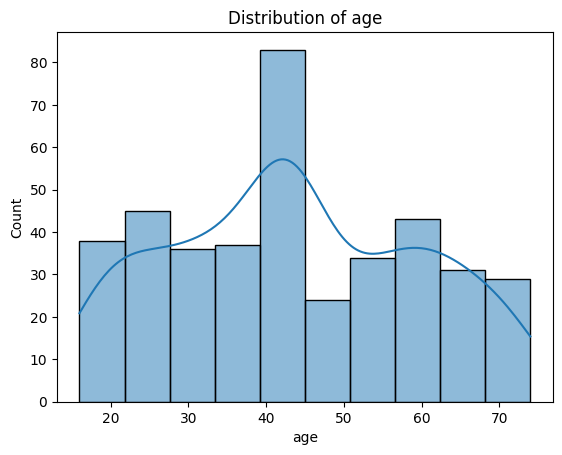

In [33]:
sns.histplot(data=df, x='age', kde=True)
plt.title(f'Distribution of {'age'}')
plt.show()

In [34]:
print("Missing newsletter values:", df['newsletter'].isna().sum())
print("Total rows:", len(df))

Missing newsletter values: 56
Total rows: 400


In [35]:
df = df.dropna(subset=['newsletter'])

In [36]:
df['newsletter'].isna().sum()

np.int64(0)

In [37]:
df.shape

(344, 9)

In [38]:
df


,user_id,email,name,signup_date,plan,country,age,spend,newsletter
0,U2067,grace3@example.com,grace,7/23/2025,pro,DE,43.0,955 INR,n
4,U2107,margaret35@example.com,margaret,08/10/2025,pro,US,43.0,1594 INR,yes
6,U2149,barbara74@example.com,barbara,2025-02-02,free,DE,29.0,NaN,yes
8,U2171,guido50@example.com,guido,6/15/2025,free,IN,30.0,628.38,false
9,U2383,ada10@example.com,ada,03/05/2025,pro,US,58.0,551 INR,no
...,...,...,...,...,...,...,...,...,...
408,U2122,alice34@example.com,alice,01/05/2025,free,US,22.0,1510.28,no
410,U2151,linus29@example.com,linus,1 Sep 2025,free,US,57.0,88.83,n
411,U2146,katherine93@example.com,katherine,4/27/2025,team,UK,32.0,NaN,yes
412,U2349,katherine99@example.com,katherine,2025-06-11,pro,UK,65.0,₹284,true


In [39]:
df['spend'].value_counts()

,count
spend,
₹156,2
₹330,2
₹780,2
314.28,1
283 INR,1
...,...
526.26,1
737.49,1
561.72,1


In [40]:
df['spend'] = (
    df['spend']
    .astype('string')
    .str.replace(r'(?i)INR|₹|Rs\.?', '', regex=True)
    .str.replace(',', '', regex=False)
    .str.strip()
)

df['spend'] = pd.to_numeric(df['spend'], errors='coerce')

In [41]:
df

,user_id,email,name,signup_date,plan,country,age,spend,newsletter
0,U2067,grace3@example.com,grace,7/23/2025,pro,DE,43.0,955.0,n
4,U2107,margaret35@example.com,margaret,08/10/2025,pro,US,43.0,1594.0,yes
6,U2149,barbara74@example.com,barbara,2025-02-02,free,DE,29.0,<NA>,yes
8,U2171,guido50@example.com,guido,6/15/2025,free,IN,30.0,628.38,false
9,U2383,ada10@example.com,ada,03/05/2025,pro,US,58.0,551.0,no
...,...,...,...,...,...,...,...,...,...
408,U2122,alice34@example.com,alice,01/05/2025,free,US,22.0,1510.28,no
410,U2151,linus29@example.com,linus,1 Sep 2025,free,US,57.0,88.83,n
411,U2146,katherine93@example.com,katherine,4/27/2025,team,UK,32.0,<NA>,yes
412,U2349,katherine99@example.com,katherine,2025-06-11,pro,UK,65.0,284.0,true


In [42]:
df['spend'] = df['spend'].fillna(df['spend'].median())

In [43]:
df.head()

,user_id,email,name,signup_date,plan,country,age,spend,newsletter
0,U2067,grace3@example.com,grace,7/23/2025,pro,DE,43.0,955.0,n
4,U2107,margaret35@example.com,margaret,08/10/2025,pro,US,43.0,1594.0,yes
6,U2149,barbara74@example.com,barbara,2025-02-02,free,DE,29.0,627.45,yes
8,U2171,guido50@example.com,guido,6/15/2025,free,IN,30.0,628.38,false
9,U2383,ada10@example.com,ada,03/05/2025,pro,US,58.0,551.0,no


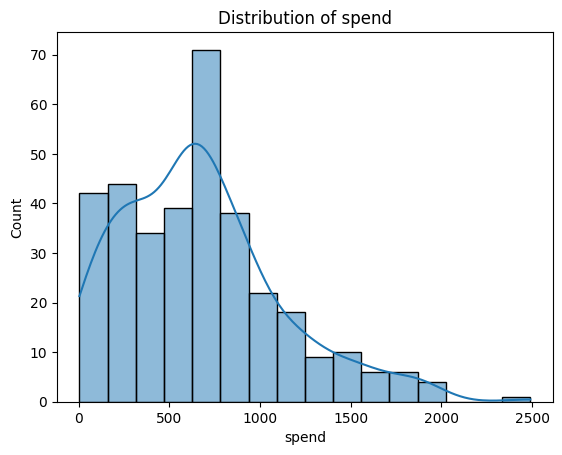

In [44]:
sns.histplot(data=df, x='spend', kde=True)
plt.title(f'Distribution of {'spend'}')
plt.show()

In [45]:
df

,user_id,email,name,signup_date,plan,country,age,spend,newsletter
0,U2067,grace3@example.com,grace,7/23/2025,pro,DE,43.0,955.0,n
4,U2107,margaret35@example.com,margaret,08/10/2025,pro,US,43.0,1594.0,yes
6,U2149,barbara74@example.com,barbara,2025-02-02,free,DE,29.0,627.45,yes
8,U2171,guido50@example.com,guido,6/15/2025,free,IN,30.0,628.38,false
9,U2383,ada10@example.com,ada,03/05/2025,pro,US,58.0,551.0,no
...,...,...,...,...,...,...,...,...,...
408,U2122,alice34@example.com,alice,01/05/2025,free,US,22.0,1510.28,no
410,U2151,linus29@example.com,linus,1 Sep 2025,free,US,57.0,88.83,n
411,U2146,katherine93@example.com,katherine,4/27/2025,team,UK,32.0,627.45,yes
412,U2349,katherine99@example.com,katherine,2025-06-11,pro,UK,65.0,284.0,true


In [46]:
df['plan'].value_counts()

,count
plan,
free,134
pro,127
team,83


In [47]:
df = pd.get_dummies(df, columns=['plan'], drop_first=True, dtype=int)

In [48]:
df

,user_id,email,name,signup_date,country,age,spend,newsletter,plan_pro,plan_team
0,U2067,grace3@example.com,grace,7/23/2025,DE,43.0,955.0,n,1,0
4,U2107,margaret35@example.com,margaret,08/10/2025,US,43.0,1594.0,yes,1,0
6,U2149,barbara74@example.com,barbara,2025-02-02,DE,29.0,627.45,yes,0,0
8,U2171,guido50@example.com,guido,6/15/2025,IN,30.0,628.38,false,0,0
9,U2383,ada10@example.com,ada,03/05/2025,US,58.0,551.0,no,1,0
...,...,...,...,...,...,...,...,...,...,...
408,U2122,alice34@example.com,alice,01/05/2025,US,22.0,1510.28,no,0,0
410,U2151,linus29@example.com,linus,1 Sep 2025,US,57.0,88.83,n,0,0
411,U2146,katherine93@example.com,katherine,4/27/2025,UK,32.0,627.45,yes,0,1
412,U2349,katherine99@example.com,katherine,2025-06-11,UK,65.0,284.0,true,1,0


In [49]:
df['newsletter'] = df['newsletter'].astype('string').str.strip().str.lower()

df['newsletter'] = df['newsletter'].map({
    'y': True,
    'yes': True,
    'true': True,
    'n': False,
    'no': False,
    'false': False
})

In [50]:
df['newsletter'] = df['newsletter'].astype(int)

In [51]:
df.head()

,user_id,email,name,signup_date,country,age,spend,newsletter,plan_pro,plan_team
0,U2067,grace3@example.com,grace,7/23/2025,DE,43.0,955.0,0,1,0
4,U2107,margaret35@example.com,margaret,08/10/2025,US,43.0,1594.0,1,1,0
6,U2149,barbara74@example.com,barbara,2025-02-02,DE,29.0,627.45,1,0,0
8,U2171,guido50@example.com,guido,6/15/2025,IN,30.0,628.38,0,0,0
9,U2383,ada10@example.com,ada,03/05/2025,US,58.0,551.0,0,1,0


In [52]:
df

,user_id,email,name,signup_date,country,age,spend,newsletter,plan_pro,plan_team
0,U2067,grace3@example.com,grace,7/23/2025,DE,43.0,955.0,0,1,0
4,U2107,margaret35@example.com,margaret,08/10/2025,US,43.0,1594.0,1,1,0
6,U2149,barbara74@example.com,barbara,2025-02-02,DE,29.0,627.45,1,0,0
8,U2171,guido50@example.com,guido,6/15/2025,IN,30.0,628.38,0,0,0
9,U2383,ada10@example.com,ada,03/05/2025,US,58.0,551.0,0,1,0
...,...,...,...,...,...,...,...,...,...,...
408,U2122,alice34@example.com,alice,01/05/2025,US,22.0,1510.28,0,0,0
410,U2151,linus29@example.com,linus,1 Sep 2025,US,57.0,88.83,0,0,0
411,U2146,katherine93@example.com,katherine,4/27/2025,UK,32.0,627.45,1,0,1
412,U2349,katherine99@example.com,katherine,2025-06-11,UK,65.0,284.0,1,1,0


In [53]:
df['signup_date'] = pd.to_datetime(
    df['signup_date'],
    format='mixed',
    errors='coerce',
    dayfirst=True
)

<Axes: xlabel='country', ylabel='count'>

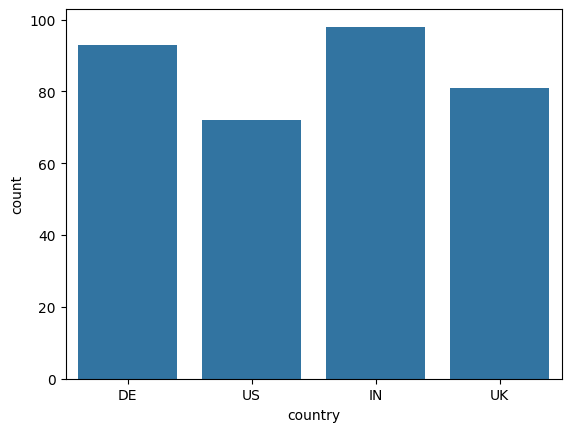

In [54]:
sns.countplot(x ='country', data = df)

In [55]:
df['year'] = df['signup_date'].dt.year
df['month'] = df['signup_date'].dt.month
df['day'] = df['signup_date'].dt.day

In [56]:
df.head()

,user_id,email,name,signup_date,country,age,spend,newsletter,plan_pro,plan_team,year,month,day
0,U2067,grace3@example.com,grace,2025-07-23,DE,43.0,955.0,0,1,0,2025,7,23
4,U2107,margaret35@example.com,margaret,2025-10-08,US,43.0,1594.0,1,1,0,2025,10,8
6,U2149,barbara74@example.com,barbara,2025-02-02,DE,29.0,627.45,1,0,0,2025,2,2
8,U2171,guido50@example.com,guido,2025-06-15,IN,30.0,628.38,0,0,0,2025,6,15
9,U2383,ada10@example.com,ada,2025-05-03,US,58.0,551.0,0,1,0,2025,5,3


In [57]:
df.drop(columns=['year', 'signup_date'], inplace=True)

In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 344 entries, 0 to 413
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   user_id     344 non-null    object 
 1   email       344 non-null    object 
 2   name        344 non-null    object 
 3   country     344 non-null    object 
 4   age         344 non-null    float64
 5   spend       344 non-null    Float64
 6   newsletter  344 non-null    int64  
 7   plan_pro    344 non-null    int64  
 8   plan_team   344 non-null    int64  
 9   month       344 non-null    int32  
 10  day         344 non-null    int32  
dtypes: Float64(1), float64(1), int32(2), int64(3), object(4)
memory usage: 29.9+ KB


In [59]:
df['country'].value_counts()

,count
country,
IN,98
DE,93
UK,81
US,72


In [60]:
df = pd.get_dummies(df, columns=['country'], dtype=int)

In [61]:
df

,user_id,email,name,age,spend,newsletter,plan_pro,plan_team,month,day,country_DE,country_IN,country_UK,country_US
0,U2067,grace3@example.com,grace,43.0,955.0,0,1,0,7,23,1,0,0,0
4,U2107,margaret35@example.com,margaret,43.0,1594.0,1,1,0,10,8,0,0,0,1
6,U2149,barbara74@example.com,barbara,29.0,627.45,1,0,0,2,2,1,0,0,0
8,U2171,guido50@example.com,guido,30.0,628.38,0,0,0,6,15,0,1,0,0
9,U2383,ada10@example.com,ada,58.0,551.0,0,1,0,5,3,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
408,U2122,alice34@example.com,alice,22.0,1510.28,0,0,0,5,1,0,0,0,1
410,U2151,linus29@example.com,linus,57.0,88.83,0,0,0,9,1,0,0,0,1
411,U2146,katherine93@example.com,katherine,32.0,627.45,1,0,1,4,27,0,0,1,0
412,U2349,katherine99@example.com,katherine,65.0,284.0,1,1,0,6,11,0,0,1,0


In [62]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 344 entries, 0 to 413
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   user_id     344 non-null    object 
 1   email       344 non-null    object 
 2   name        344 non-null    object 
 3   age         344 non-null    float64
 4   spend       344 non-null    Float64
 5   newsletter  344 non-null    int64  
 6   plan_pro    344 non-null    int64  
 7   plan_team   344 non-null    int64  
 8   month       344 non-null    int32  
 9   day         344 non-null    int32  
 10  country_DE  344 non-null    int64  
 11  country_IN  344 non-null    int64  
 12  country_UK  344 non-null    int64  
 13  country_US  344 non-null    int64  
dtypes: Float64(1), float64(1), int32(2), int64(7), object(3)
memory usage: 38.0+ KB


<Axes: >

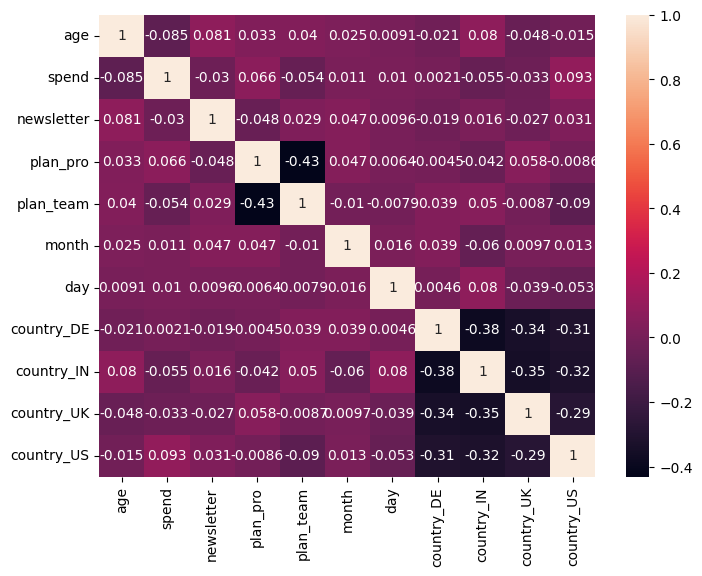

In [63]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)

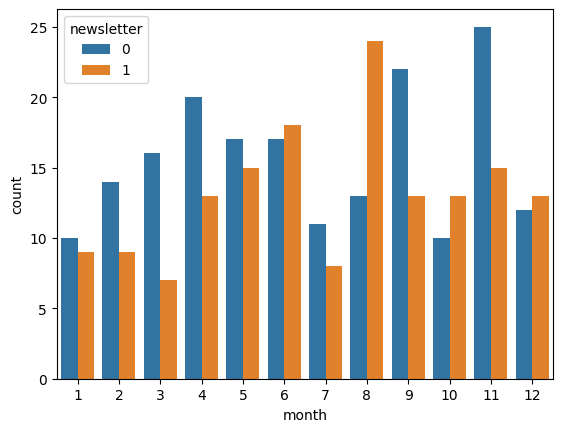

In [64]:
sns.countplot(data=df, x='month', hue='newsletter')

plt.show()

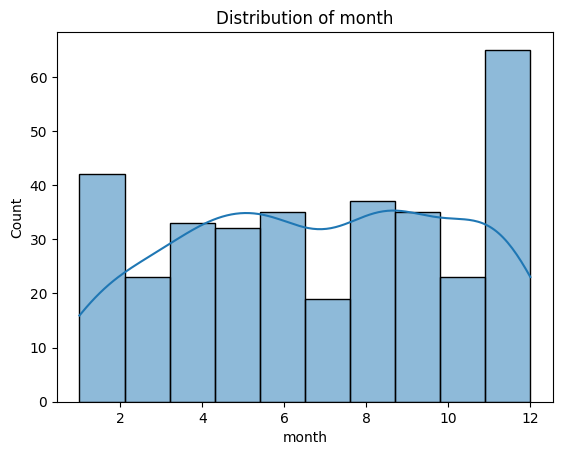

In [65]:
sns.histplot(data=df, x='month', kde=True)
plt.title(f'Distribution of {'month'}')
plt.show()

In [66]:
df.columns

Index(['user_id', 'email', 'name', 'age', 'spend', 'newsletter', 'plan_pro',
       'plan_team', 'month', 'day', 'country_DE', 'country_IN', 'country_UK',
       'country_US'],
      dtype='object')

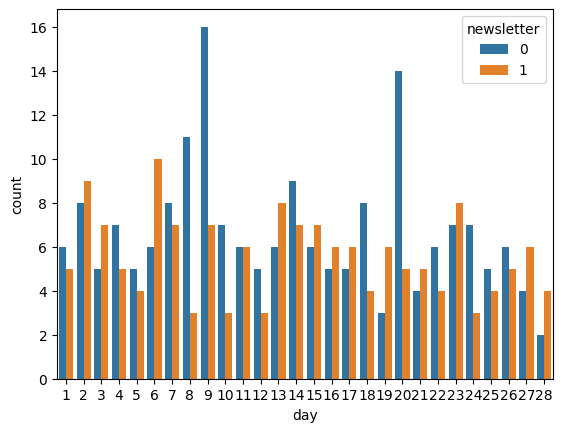

In [67]:
sns.countplot(data=df, x='day', hue='newsletter')

plt.show()

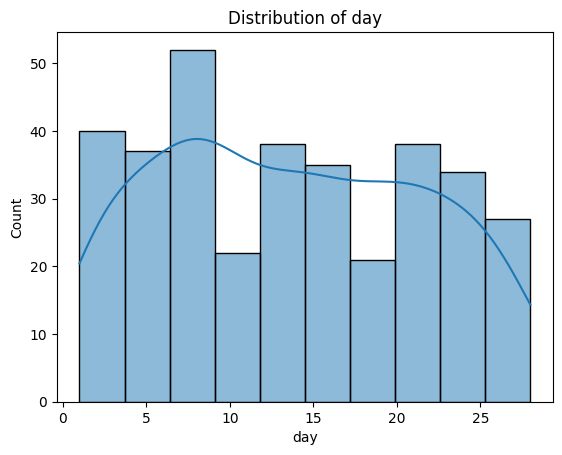

In [68]:
sns.histplot(data=df, x='day', kde=True)
plt.title(f'Distribution of {'day'}')
plt.show()

In [69]:
df.drop(columns=['country_DE'], inplace=True)

In [70]:
df.head()

,user_id,email,name,age,spend,newsletter,plan_pro,plan_team,month,day,country_IN,country_UK,country_US
0,U2067,grace3@example.com,grace,43.0,955.0,0,1,0,7,23,0,0,0
4,U2107,margaret35@example.com,margaret,43.0,1594.0,1,1,0,10,8,0,0,1
6,U2149,barbara74@example.com,barbara,29.0,627.45,1,0,0,2,2,0,0,0
8,U2171,guido50@example.com,guido,30.0,628.38,0,0,0,6,15,1,0,0
9,U2383,ada10@example.com,ada,58.0,551.0,0,1,0,5,3,0,0,1


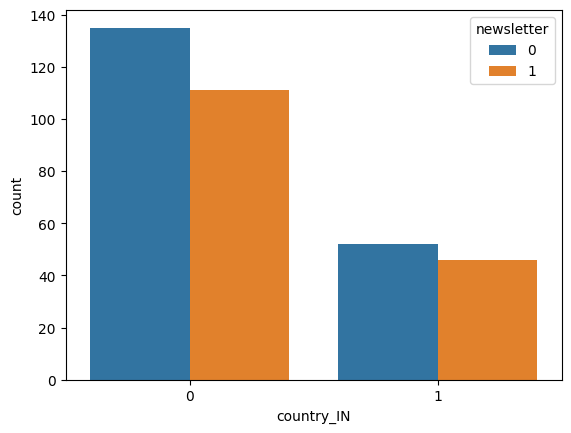

In [71]:
sns.countplot(data=df, x='country_IN', hue='newsletter')

plt.show()

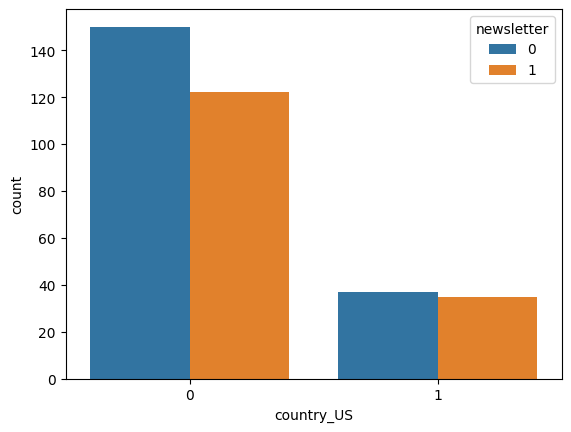

In [72]:
sns.countplot(data=df, x='country_US', hue='newsletter')

plt.show()

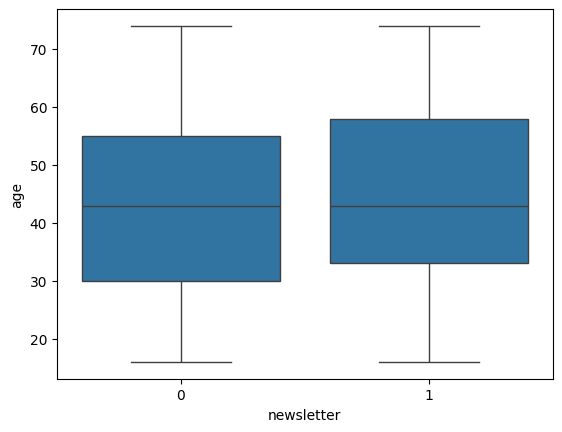

In [73]:
sns.boxplot(data=df, x='newsletter', y='age')
plt.show()

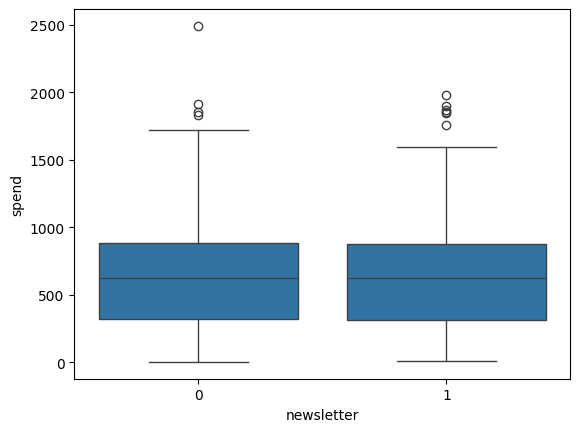

In [74]:
sns.boxplot(data=df, x='newsletter', y='spend')
plt.show()

In [75]:
df.head()

,user_id,email,name,age,spend,newsletter,plan_pro,plan_team,month,day,country_IN,country_UK,country_US
0,U2067,grace3@example.com,grace,43.0,955.0,0,1,0,7,23,0,0,0
4,U2107,margaret35@example.com,margaret,43.0,1594.0,1,1,0,10,8,0,0,1
6,U2149,barbara74@example.com,barbara,29.0,627.45,1,0,0,2,2,0,0,0
8,U2171,guido50@example.com,guido,30.0,628.38,0,0,0,6,15,1,0,0
9,U2383,ada10@example.com,ada,58.0,551.0,0,1,0,5,3,0,0,1


In [76]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df[['age', 'spend', 'month', 'day']] = scaler.fit_transform(
    df[['age', 'spend', 'month', 'day']]
)

In [77]:
df.head()

,user_id,email,name,age,spend,newsletter,plan_pro,plan_team,month,day,country_IN,country_UK,country_US
0,U2067,grace3@example.com,grace,-0.017516,0.653738,0,1,0,0.051229,1.199682,0,0,0
4,U2107,margaret35@example.com,margaret,-0.017516,2.090303,1,1,0,0.962749,-0.725181,0,0,1
6,U2149,barbara74@example.com,barbara,-0.905504,-0.082642,1,0,0,-1.467971,-1.495126,0,0,0
8,U2171,guido50@example.com,guido,-0.842077,-0.080551,0,0,0,-0.252611,0.173088,1,0,0
9,U2383,ada10@example.com,ada,0.933899,-0.254512,0,1,0,-0.556451,-1.366802,0,0,1


In [78]:
df_cleaned = df.copy()

In [79]:
df_cleaned

,user_id,email,name,age,spend,newsletter,plan_pro,plan_team,month,day,country_IN,country_UK,country_US
0,U2067,grace3@example.com,grace,-0.017516,0.653738,0,1,0,0.051229,1.199682,0,0,0
4,U2107,margaret35@example.com,margaret,-0.017516,2.090303,1,1,0,0.962749,-0.725181,0,0,1
6,U2149,barbara74@example.com,barbara,-0.905504,-0.082642,1,0,0,-1.467971,-1.495126,0,0,0
8,U2171,guido50@example.com,guido,-0.842077,-0.080551,0,0,0,-0.252611,0.173088,1,0,0
9,U2383,ada10@example.com,ada,0.933899,-0.254512,0,1,0,-0.556451,-1.366802,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
408,U2122,alice34@example.com,alice,-1.349498,1.902088,0,0,0,-0.556451,-1.623450,0,0,1
410,U2151,linus29@example.com,linus,0.870471,-1.293538,0,0,0,0.658909,-1.623450,0,0,1
411,U2146,katherine93@example.com,katherine,-0.715221,-0.082642,1,0,1,-0.860291,1.712979,0,1,0
412,U2349,katherine99@example.com,katherine,1.377893,-0.854767,1,1,0,-0.252611,-0.340208,0,1,0


In [80]:
X = df_cleaned[['age', 'spend', 'plan_pro', 'plan_team',
        'country_IN', 'country_UK', 'country_US',
        'month', 'day']]

y = df_cleaned['newsletter']

In [81]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [82]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [83]:

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [84]:
y_pred = model.predict(X_test)

In [85]:
y_pred

array([0.47363336, 0.36296983, 0.39132976, 0.330182  , 0.49153512,
       0.41579505, 0.43889069, 0.43166725, 0.41527779, 0.5149826 ,
       0.44195966, 0.44792095, 0.40107287, 0.35999389, 0.44493225,
       0.51956572, 0.39086287, 0.59017648, 0.58855106, 0.46087492,
       0.48373096, 0.57071522, 0.41978923, 0.52046528, 0.39525766,
       0.37615423, 0.45560044, 0.57300558, 0.45626404, 0.57425122,
       0.55510342, 0.55017371, 0.46262144, 0.48888677, 0.43054279,
       0.45520096, 0.48517568, 0.47157111, 0.50631262, 0.4060603 ,
       0.3918346 , 0.47165169, 0.42994911, 0.48774681, 0.50405854,
       0.42170576, 0.41308988, 0.33084092, 0.414393  , 0.36603099,
       0.57669604, 0.46938832, 0.4399466 , 0.43661742, 0.45040706,
       0.55830071, 0.36778919, 0.44037085, 0.5408845 , 0.50963048,
       0.44048229, 0.43415132, 0.43218111, 0.50916539, 0.39304916,
       0.48167312, 0.47058832, 0.58474705, 0.56070066])

In [86]:
r2 = r2_score( y_test,y_pred)
r2

-0.029265092975054863